# Module 2 · My dataset
This notebook uses **your** `src/data.py` (built with Claude from `docs/data_spec.md`) and **your** `project.yaml`.
Run it top to bottom. The numbers and the grid go into Assignment 2.2. The observations at the end are **yours**.

In [8]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import matplotlib.pyplot as plt
from src import data as dt
project = dt.load_project("project.yaml")
classes = project["classes"]
print(project)

{'name': 'bottles', 'classes': ['bottle'], 'format': 'yolo', 'source': {'kaggle': 'siddharthkumarsah/plastic-bottles-image-dataset'}}


## 1. Retrieve the data
Kaggle downloads once (later runs reuse the copy).

In [9]:
raw = dt.download(project)
print("raw dataset in:", raw)

raw dataset in: C:\Users\yayab\.cache\kagglehub\datasets\siddharthkumarsah\plastic-bottles-image-dataset\versions\2


## 2. Convert it to one YOLO folder with a fixed split

In [10]:
root = dt.prepare(project, raw)
print("dataset ready in:", root)

dataset ready in: data\bottles_yolo


## 3. Boxes per class — is it balanced?

train {'bottle': 3186}
val {'bottle': 1550}
test {'bottle': 792}


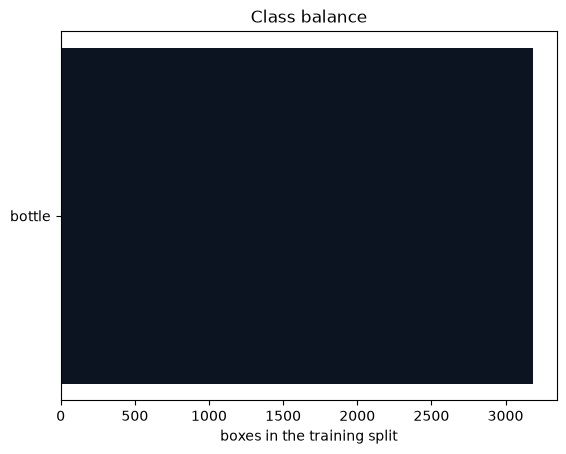

In [11]:
cc = dt.class_counts(root, classes)
for split, counts in cc.items(): print(split, counts)
plt.barh(classes, [cc["train"][c] for c in classes], color="#0C1422")
plt.xlabel("boxes in the training split"); plt.title("Class balance"); plt.show()

## 4. Images, boxes and box sizes per split

In [12]:
for split, s in dt.split_stats(root).items(): print(split, s)

train {'images': 2177, 'boxes': 3186, 'boxes_per_image': 1.46, 'median_box_area_pct': 16.43, 'small_boxes_lt_1pct': 280}
val {'images': 1174, 'boxes': 1550, 'boxes_per_image': 1.32, 'median_box_area_pct': 15.35, 'small_boxes_lt_1pct': 123}
test {'images': 648, 'boxes': 792, 'boxes_per_image': 1.22, 'median_box_area_pct': 14.18, 'small_boxes_lt_1pct': 64}


## 5. Quality checks before trusting the data

In [13]:
rv = dt.review(root, len(classes))
for k, v in rv["counts"].items(): print(f"{k:28s} {v:5d}   {rv['examples'][k][:3]}")

images_without_label             0   []
labels_without_image             0   []
empty_labels                     0   []
out_of_range_boxes              25   ['test/bottle-208-_JPG.rf.735985d60ddb924c219f923adfbd0f82', 'test/bottle-280-_JPG.rf.95e4c5fa004537f4d8b49c101c4b1847', 'test/bottle-334-_JPG.rf.e2925e5dd3dce14a85da6cf35bd53033']
unknown_class_ids                0   []
tiny_boxes_lt_0.1pct           116   ['test/25_jpg.rf.442c800d667cfa1019930f957b9a04fb', 'test/56_jpg.rf.edae0a1dfb5a74e2dc93d2df570f7206', 'test/bottle-208-_JPG.rf.735985d60ddb924c219f923adfbd0f82']
duplicates_across_splits        16   ['train/empty-plastic-bottle-lying-around-park-ground-empty-plastic-bottle-lying-around-park-ground-146271701_jpg.rf.00152ad7ce88048bcf9815e69567a6fc = val/waterbottle211_jpg.rf.13876b72c714846be4a1245104cc44de', 'train/empty-plastic-water-bottle-500x500_jpg.rf.c7a67b6cf1ef5dde76ddb785eec5704f = val/waterbottle229_jpg.rf.5f68bf62aff29f3f95397ca28c3eefce', 'train/plastic234_jpg.rf.46

## 6. The 20-image inspection
Open the 20 images, compare every box with what you see.

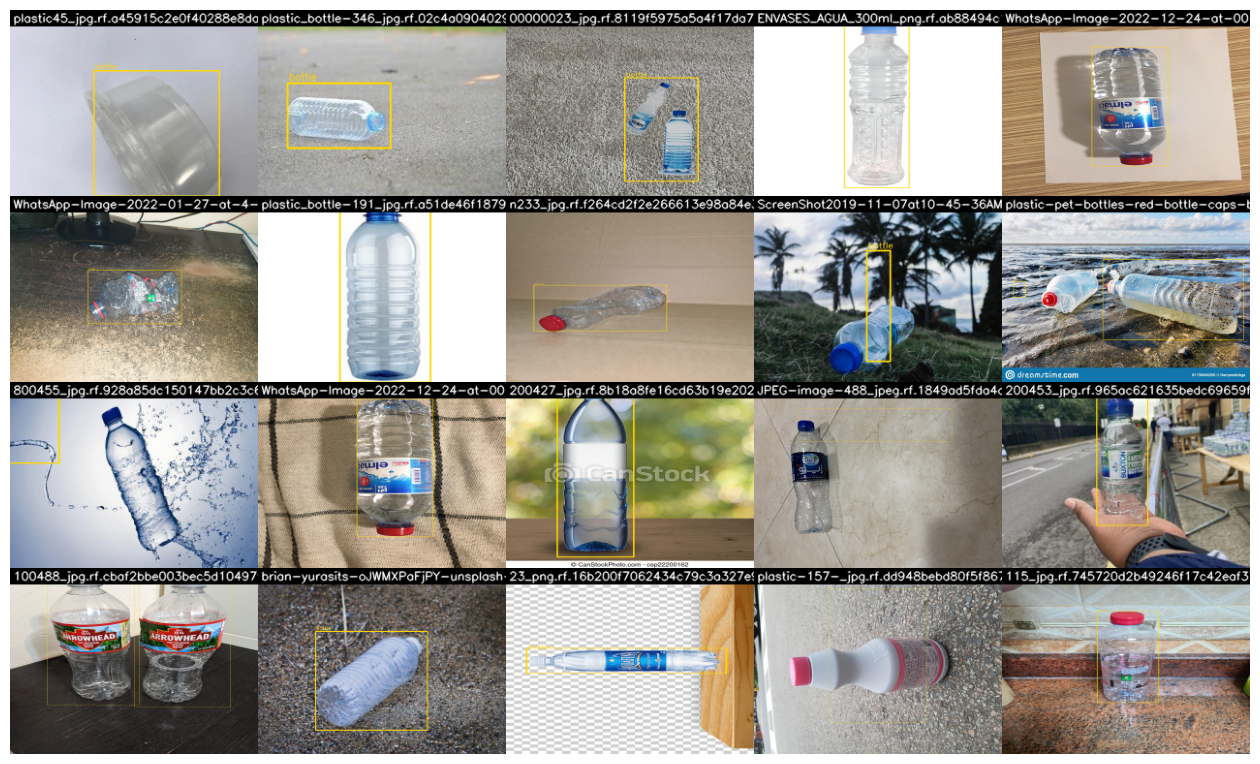

results\dataset_review.md


In [14]:
grid = dt.sample_grid(root, "train", n=20, seed=0, classes=classes)
plt.figure(figsize=(16, 10)); plt.imshow(grid); plt.axis("off"); plt.show()
print(dt.write_report(root, classes))      # results/dataset_review.md + results/dataset_sample_grid.jpg

## My observations (write them yourself — Assignment 2.2)

**Boxes that do not match what I see** (image name, what is wrong):
- `00000023_jpg` (top row, third image): two bottles appear inside one bounding box instead of having a separate box each.
- `ScreenShot2019-11-07` (second row, fourth image): the bounding box is too narrow and does not cover the entire bottle.
- `JPEG-image-488_jpeg` (third row, fourth image): the bounding box is misplaced and covers part of the floor instead of properly surrounding the bottle.

**Class balance** (which class has the fewest boxes, and what that may cause):
- The dataset contains only one class, bottle, with 5,528 boxes in total (3,186 in train).
- There are no other classes to compare, so there is no imbalance to measure.
- This means a model trained on it cannot learn to distinguish reusable bottles from disposable ones.

**The two things most likely to make this dataset hard:**
1. **Incorrect bounding boxes.** Some boxes do not properly surround the bottles, which can confuse the model during training. The quality checks also found 25 out-of-range boxes and 116 very tiny boxes.
2. **Very different photos.** The images have different backgrounds, lighting, angles, and bottle positions.